# Fase 3: Uji Coba K-Means & Evaluasi Metrik Silhouette

Tahapan ini merupakan proses inti dari *machine learning* yang kita bangun. Kita akan menerapkan algoritma **K-Means Clustering** ke seluruh representasi data yang dihasilkan pada Tahap 2 (total 8 matriks dari alur 204 → 203 → 74 → 37). Penentuan model terbaik akan didasarkan pada skor **Silhouette Coefficient**.

---

## Landasan Teori

### 1. K-Means Clustering
Algoritma ini bertugas mempartisi sekumpulan sampel data ke dalam $k$ kelompok (cluster). Tujuan utamanya adalah meminimalkan jarak kuadrat antara titik data dengan titik pusat (*centroid*) dari masing-masing cluster.

**Langkah kerja K-Means:**
1. Menentukan $k$ titik awal secara strategis (menggunakan metode `k-means++`).
2. Menghubungkan setiap sampel data ke centroid terdekat.
3. Menghitung ulang posisi centroid berdasarkan rata-rata sampel di dalam kelompok tersebut.
4. Melakukan iterasi langkah 2 dan 3 hingga posisi centroid stabil (konvergen).

### 2. Silhouette Coefficient
Metrik ini digunakan untuk mengukur seberapa solid sebuah cluster. Formulanya membandingkan kedekatan antar-sampel dalam satu cluster yang sama ($a$) dengan jarak ke cluster tetangga terdekat ($b$).

Rentang nilai Silhouette berkisar antara **-1 hingga +1**:
- Mendekati **+1**: Sampel berada di kelompok yang sangat tepat dan jauh dari kelompok lain.
- Mendekati **0**: Sampel berada tepat di perbatasan dua kelompok.
- Mendekati **-1**: Sampel kemungkinan besar salah klasifikasi (berada di cluster yang salah).

### 3. Metode Siku (Elbow)
Pendekatan visual untuk melihat penurunan nilai *Inertia* (jarak kuadrat ke pusat cluster). Titik di mana kurva mulai melandai tajam (membentuk siku) seringkali merupakan indikasi jumlah cluster yang optimal. Kita akan mengkombinasikan metode ini dengan skor Silhouette untuk validasi silang.

---

## Skenario Uji Coba
- **Sumber Data**: 8 format matriks (Linier & Polinomial pada dimensi 204, 203, 74, dan 37)
- **Rentang Cluster ($k$)**: 2 hingga 10
- **Total Uji Coba**: 72 eksekusi K-Means independen
- **Parameter Model**: `n_init=20` (20 kali inisialisasi centroid), `random_state=42`


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

# Pengaturan visual
plt.rcParams['figure.figsize'] = (14, 6)
sns.set_theme(style='darkgrid', font_scale=1.0)

DIR_INPUT = '../data/hasil_tahap2'
DIR_OUTPUT = '../data/hasil_tahap3'
os.makedirs(DIR_OUTPUT, exist_ok=True)

# ── 3.1 Memuat Data Tahap 2 ───────────────────────────────────
jalur_data = os.path.join(DIR_INPUT, 'koleksi_data_tahap2.pkl')
with open(jalur_data, 'rb') as arsip:
    paket_data = pickle.load(arsip)

kumpulan_matriks = paket_data['koleksi_matriks']
meta_lin = paket_data['metadata_lin']
meta_pol = paket_data['metadata_pol']
df_asli_lin = paket_data['dataframe_asli_lin']
df_asli_pol = paket_data['dataframe_asli_pol']

print("✓ Paket data Tahap 2 berhasil dimuat.")
print(f"✓ Jumlah matriks representasi: {len(kumpulan_matriks)}")
print("\nDaftar Struktur Matriks:")
for nama_kunci, matriks in kumpulan_matriks.items():
    print(f" ⏵ {nama_kunci:<20} | Dimensi: {matriks.shape}")


✓ Paket data Tahap 2 berhasil dimuat.
✓ Jumlah matriks representasi: 8

Daftar Struktur Matriks:
 ⏵ Linier_Asli_204      | Dimensi: (37, 204)
 ⏵ Linier_Fase1_203     | Dimensi: (37, 203)
 ⏵ Linier_Fase2_74      | Dimensi: (37, 74)
 ⏵ Linier_Fase3_37      | Dimensi: (37, 37)
 ⏵ Polinom_Asli_204     | Dimensi: (37, 204)
 ⏵ Polinom_Fase1_203    | Dimensi: (37, 203)
 ⏵ Polinom_Fase2_74     | Dimensi: (37, 74)
 ⏵ Polinom_Fase3_37     | Dimensi: (37, 37)


## 3.2 Eksekusi 72 Skenario K-Means

Kita akan melakukan *looping* untuk menguji $k=2$ hingga $k=10$ pada 8 dataset yang ada.


In [2]:
RENTANG_K = range(2, 11)
INISIALISASI = 20
SEED_ACAK = 42

rekam_jejak = []
peta_label = {}
total_skenario = len(kumpulan_matriks) * len(RENTANG_K)
hitungan_run = 0

print(f"Memulai iterasi untuk {total_skenario} skenario K-Means...")
print("-" * 60)

for nama_dataset, matriks_X in kumpulan_matriks.items():
    skor_sil_tertinggi = -1
    k_andalan = 2
    
    for k_uji in RENTANG_K:
        hitungan_run += 1
        model_km = KMeans(n_clusters=k_uji, n_init=INISIALISASI, random_state=SEED_ACAK, init='k-means++')
        prediksi_label = model_km.fit_predict(matriks_X)
        
        # Standarisasi Penamaan Cluster:
        # Cluster 0 akan selalu merujuk pada cluster dengan anggota terbanyak.
        distribusi_anggota = np.bincount(prediksi_label, minlength=k_uji)
        urutan_besar_ke_kecil = np.argsort(-distribusi_anggota, kind='stable')
        kamus_mapping = np.empty(k_uji, dtype=int)
        kamus_mapping[urutan_besar_ke_kecil] = np.arange(k_uji)
        
        prediksi_label_terurut = kamus_mapping[prediksi_label]
        
        # Kalkulasi Metrik
        nilai_silhouette = silhouette_score(matriks_X, prediksi_label_terurut)
        nilai_inertia = model_km.inertia_
        
        peta_label[(nama_dataset, k_uji)] = prediksi_label_terurut
        
        rekam_jejak.append({
            'Entitas_Data': nama_dataset,
            'Nilai_K': k_uji,
            'Skor_Silhouette': round(nilai_silhouette, 5),
            'Skor_Inertia': round(nilai_inertia, 3)
        })
        
        if nilai_silhouette > skor_sil_tertinggi:
            skor_sil_tertinggi = nilai_silhouette
            k_andalan = k_uji
            
    print(f" ➤ {nama_dataset:<20} | K-Optimal: {k_andalan} | Silhouette: {skor_sil_tertinggi:.4f}")

df_evaluasi = pd.DataFrame(rekam_jejak)
print(f"\nProses Selesai. Seluruh {hitungan_run} model telah dibangun dan dievaluasi.")


Memulai iterasi untuk 72 skenario K-Means...
------------------------------------------------------------
 ➤ Linier_Asli_204      | K-Optimal: 2 | Silhouette: 0.4909
 ➤ Linier_Fase1_203     | K-Optimal: 2 | Silhouette: 0.4909
 ➤ Linier_Fase2_74      | K-Optimal: 2 | Silhouette: 0.4021
 ➤ Linier_Fase3_37      | K-Optimal: 2 | Silhouette: 0.4021
 ➤ Polinom_Asli_204     | K-Optimal: 2 | Silhouette: 0.5375
 ➤ Polinom_Fase1_203    | K-Optimal: 2 | Silhouette: 0.5375
 ➤ Polinom_Fase2_74     | K-Optimal: 3 | Silhouette: 0.4543
 ➤ Polinom_Fase3_37     | K-Optimal: 3 | Silhouette: 0.4543

Proses Selesai. Seluruh 72 model telah dibangun dan dievaluasi.


## 3.3 Visualisasi Kurva Silhouette (Evaluasi Tiap Dataset)

Mari kita lihat bagaimana pergerakan skor Silhouette seiring dengan bertambahnya nilai $k$. Titik bintang merepresentasikan konfigurasi terbaik untuk masing-masing matriks.


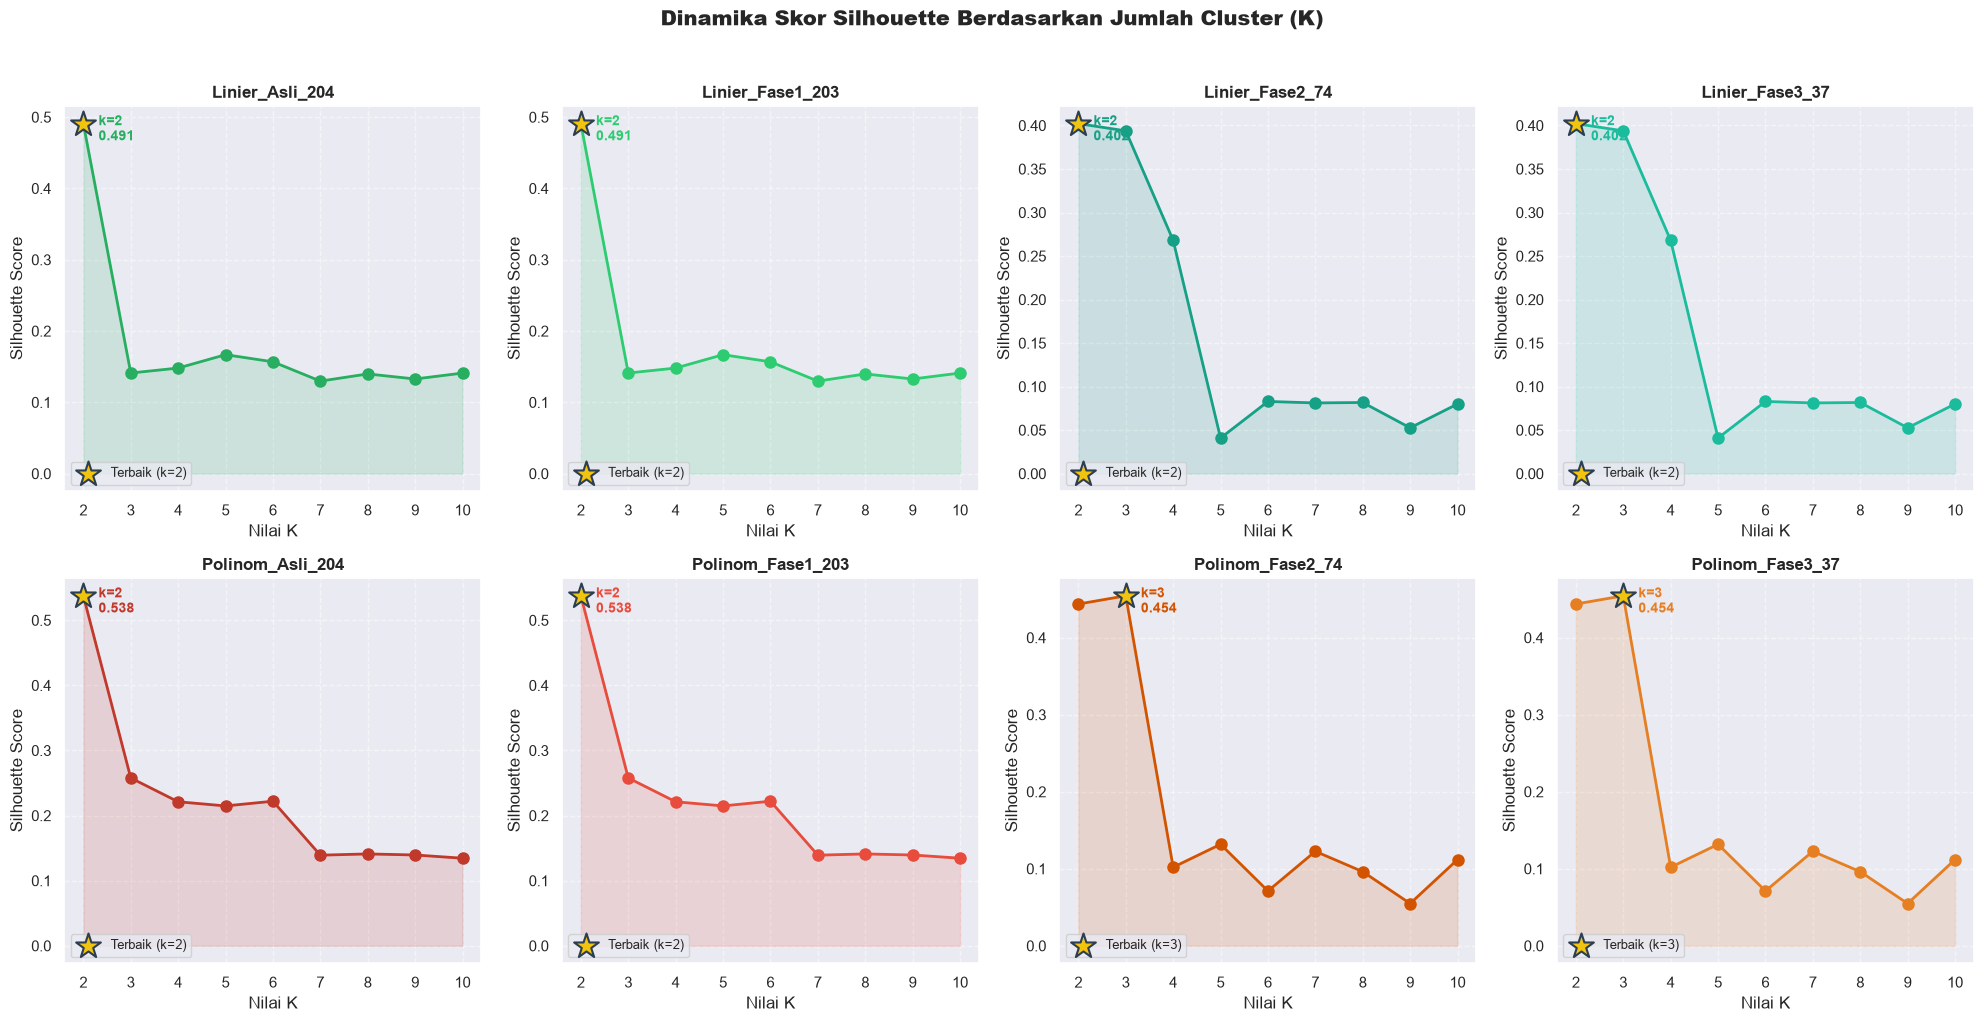

In [3]:
# Mapping warna untuk setiap versi data
WARNA_TEMA = {
    'Linier_Asli_204': '#27ae60', 'Linier_Fase1_203': '#2ecc71',
    'Linier_Fase2_74': '#16a085', 'Linier_Fase3_37': '#1abc9c',
    'Polinom_Asli_204': '#c0392b', 'Polinom_Fase1_203': '#e74c3c',
    'Polinom_Fase2_74': '#d35400', 'Polinom_Fase3_37': '#e67e22'
}

fig, kanvas = plt.subplots(2, 4, figsize=(20, 10))
kanvas = kanvas.flatten()

for indeks, (kunci_data, _) in enumerate(kumpulan_matriks.items()):
    ax = kanvas[indeks]
    potongan_df = df_evaluasi[df_evaluasi['Entitas_Data'] == kunci_data]
    kode_warna = WARNA_TEMA.get(kunci_data, '#34495e')
    
    ax.plot(potongan_df['Nilai_K'], potongan_df['Skor_Silhouette'], marker='o', 
            color=kode_warna, linewidth=2, markersize=8, zorder=3)
    ax.fill_between(potongan_df['Nilai_K'], potongan_df['Skor_Silhouette'], 
                    alpha=0.15, color=kode_warna)
    
    # Deteksi dan tandai titik optimum
    baris_terbaik = potongan_df.loc[potongan_df['Skor_Silhouette'].idxmax()]
    k_opt = int(baris_terbaik['Nilai_K'])
    sil_opt = baris_terbaik['Skor_Silhouette']
    
    ax.scatter(k_opt, sil_opt, s=350, color='#f1c40f', edgecolor='#2c3e50', 
               linewidth=1.5, marker='*', zorder=5, label=f'Terbaik (k={k_opt})')
    
    anotasi_teks = f" k={k_opt}\n {sil_opt:.3f}"
    ax.annotate(anotasi_teks, xy=(k_opt, sil_opt), xytext=(8, -12),
                textcoords='offset points', fontsize=10, fontweight='bold', color=kode_warna)
    
    ax.set_title(kunci_data, fontweight='bold', fontsize=12)
    ax.set_xticks(list(RENTANG_K))
    ax.set_ylabel('Silhouette Score')
    ax.set_xlabel('Nilai K')
    ax.legend(loc='lower left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Dinamika Skor Silhouette Berdasarkan Jumlah Cluster (K)', fontsize=15, fontweight='black', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '01_kurva_silhouette_kolektif.png'), dpi=120)
plt.show()


## 3.4 Klasemen dan Penentuan Konfigurasi Global Terbaik

Menyaring 1 kombinasi terbaik dari masing-masing dataset, kemudian memilih satu pemenang mutlak (Global Best) untuk dianalisis lebih dalam.


In [4]:
tabel_juara_tiap_data = (
    df_evaluasi.loc[df_evaluasi.groupby('Entitas_Data', sort=False)['Skor_Silhouette'].idxmax()]
    .sort_values('Skor_Silhouette', ascending=False)
    .reset_index(drop=True)
)
tabel_juara_tiap_data.index += 1

print("--- RINGKASAN KONFIGURASI TERBAIK PER DATASET ---")
print(tabel_juara_tiap_data.to_string())
tabel_juara_tiap_data.to_csv(os.path.join(DIR_OUTPUT, 'klasemen_cluster.csv'))

# Ekstraksi Pemenang Global
baris_jawara_dunia = df_evaluasi.loc[df_evaluasi['Skor_Silhouette'].idxmax()]
DATASET_JUARA = baris_jawara_dunia['Entitas_Data']
K_JUARA = int(baris_jawara_dunia['Nilai_K'])
SILHOUETTE_JUARA = baris_jawara_dunia['Skor_Silhouette']
LABEL_JUARA = peta_label[(DATASET_JUARA, K_JUARA)]

print("\n🏆 🏆 KONFIGURASI GLOBAL TERBAIK 🏆 🏆")
print(f" ~ Representasi   : {DATASET_JUARA}")
print(f" ~ Jumlah Cluster : {K_JUARA}")
print(f" ~ Skor Silhouette: {SILHOUETTE_JUARA:.4f}")


--- RINGKASAN KONFIGURASI TERBAIK PER DATASET ---
        Entitas_Data  Nilai_K  Skor_Silhouette  Skor_Inertia
1  Polinom_Fase1_203        2          0.53755      5450.817
2   Polinom_Asli_204        2          0.53755      5450.817
3    Linier_Asli_204        2          0.49086      5442.270
4   Linier_Fase1_203        2          0.49086      5442.270
5   Polinom_Fase2_74        3          0.45432      1968.616
6   Polinom_Fase3_37        3          0.45432      1968.616
7    Linier_Fase3_37        2          0.40214      2226.972
8    Linier_Fase2_74        2          0.40214      2226.972

🏆 🏆 KONFIGURASI GLOBAL TERBAIK 🏆 🏆
 ~ Representasi   : Polinom_Asli_204
 ~ Jumlah Cluster : 2
 ~ Skor Silhouette: 0.5375


## 3.5 Pemantauan Kestabilan Partisi di Tiap Fase Reduksi (204 → 203 → 74 → 37)

Apakah reduksi atribut mengubah struktur kelompok wilayah? Kita bisa mengeceknya menggunakan *Adjusted Rand Index*. Jika nilainya mendekati 1.0, berarti komposisi wilayah di dalam cluster tidak berubah meskipun jumlah fiturnya menyusut drastis.


--- JEJAK STABILITAS KELOMPOK SELAMA REDUKSI DIMENSI ---
Garis Keturunan  Sisa Atribut  K Ideal  Silhouette Distribusi Wilayah                         Stabilitas
         Linier           204        2      0.4909             34 | 3                                   
         Linier           203        2      0.4909             34 | 3 Identik dengan formasi 204 atribut
         Linier            74        2      0.4021             33 | 4                                   
         Linier            37        2      0.4021             33 | 4  Identik dengan formasi 74 atribut
        Polinom           204        2      0.5376             35 | 2                                   
        Polinom           203        2      0.5376             35 | 2 Identik dengan formasi 204 atribut
        Polinom            74        3      0.4543         35 | 1 | 1                                   
        Polinom            37        3      0.4543         35 | 1 | 1  Identik dengan formasi 74 atribu

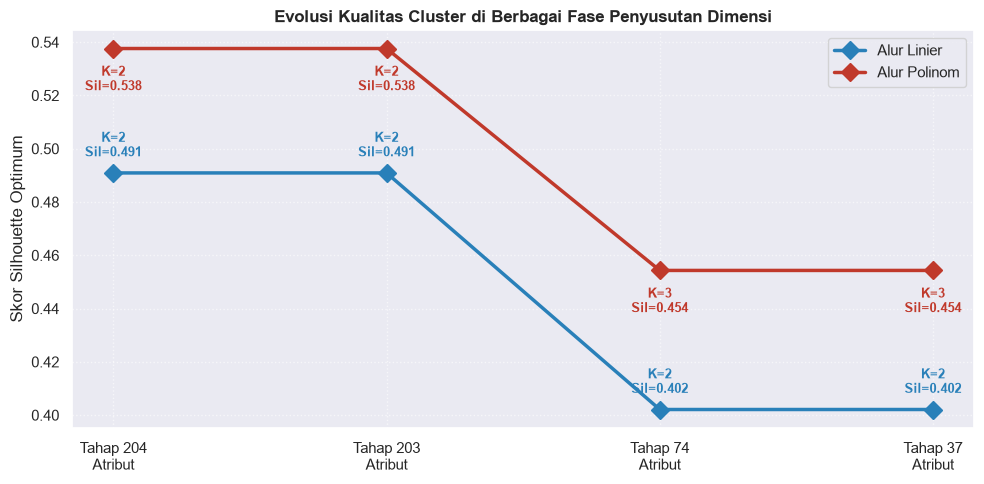

In [5]:
DIMENSI_ALUR = [204, 203, 74, 37]
METODE_INTERPOLASI = ['Linier', 'Polinom']

rekap_jejak_dimensi = []

for met in METODE_INTERPOLASI:
    info_sebelumnya = None
    for dim in DIMENSI_ALUR:
        # Rekonstruksi nama kunci (contoh: Polinom_Fase2_74)
        if dim == 204: nama_kunci = f"{met}_Asli_204"
        elif dim == 203: nama_kunci = f"{met}_Fase1_203"
        elif dim == 74: nama_kunci = f"{met}_Fase2_74"
        else: nama_kunci = f"{met}_Fase3_37"
        
        if nama_kunci not in kumpulan_matriks: continue
        
        # Ambil konfigurasi terbaik untuk nama_kunci ini
        potongan = df_evaluasi[df_evaluasi['Entitas_Data'] == nama_kunci]
        juara_lokal = potongan.loc[potongan['Skor_Silhouette'].idxmax()]
        k_lok = int(juara_lokal['Nilai_K'])
        lbl_lok = peta_label[(nama_kunci, k_lok)]
        sil_lok = juara_lokal['Skor_Silhouette']
        
        status_partisi = ""
        if info_sebelumnya is not None and info_sebelumnya['k'] == k_lok:
            skor_ari = adjusted_rand_score(info_sebelumnya['lbl'], lbl_lok)
            if skor_ari > 0.99:
                status_partisi = f"Identik dengan formasi {info_sebelumnya['dim']} atribut"
                
        rekap_jejak_dimensi.append({
            'Garis Keturunan': met,
            'Sisa Atribut': dim,
            'K Ideal': k_lok,
            'Silhouette': round(sil_lok, 4),
            'Distribusi Wilayah': " | ".join(map(str, np.bincount(lbl_lok, minlength=k_lok))),
            'Stabilitas': status_partisi
        })
        
        info_sebelumnya = {'dim': dim, 'k': k_lok, 'lbl': lbl_lok}

df_stabilitas = pd.DataFrame(rekap_jejak_dimensi)
print("--- JEJAK STABILITAS KELOMPOK SELAMA REDUKSI DIMENSI ---")
print(df_stabilitas.to_string(index=False))

# Plot evolusi nilai silhouette
fig, ax = plt.subplots(figsize=(10, 5))
sumbu_x = np.arange(len(DIMENSI_ALUR))

for met, warna in zip(['Linier', 'Polinom'], ['#2980b9', '#c0392b']):
    subset = df_stabilitas[df_stabilitas['Garis Keturunan'] == met]
    ax.plot(sumbu_x, subset['Silhouette'], marker='D', markersize=9, 
            linewidth=2.5, color=warna, label=f'Alur {met}')
    
    for i, (_, baris) in enumerate(subset.iterrows()):
        teks_ano = f"K={baris['K Ideal']}\nSil={baris['Silhouette']:.3f}"
        offset_y = 12 if met == 'Linier' else -30
        ax.annotate(teks_ano, xy=(i, baris['Silhouette']), xytext=(0, offset_y),
                    textcoords='offset points', ha='center', fontweight='bold', color=warna, fontsize=9)

ax.set_xticks(sumbu_x)
ax.set_xticklabels([f"Tahap {d}\nAtribut" for d in DIMENSI_ALUR])
ax.set_title('Evolusi Kualitas Cluster di Berbagai Fase Penyusutan Dimensi', fontweight='bold')
ax.set_ylabel('Skor Silhouette Optimum')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '02_evolusi_dimensi.png'), dpi=120)
plt.show()


## 3.6 Peta Suhu (Heatmap) Komprehensif

Menampilkan keseluruhan matriks hasil eksperimen. Area yang menyala lebih terang menunjukkan konfigurasi clustering yang sangat terpisah (kualitas tinggi).


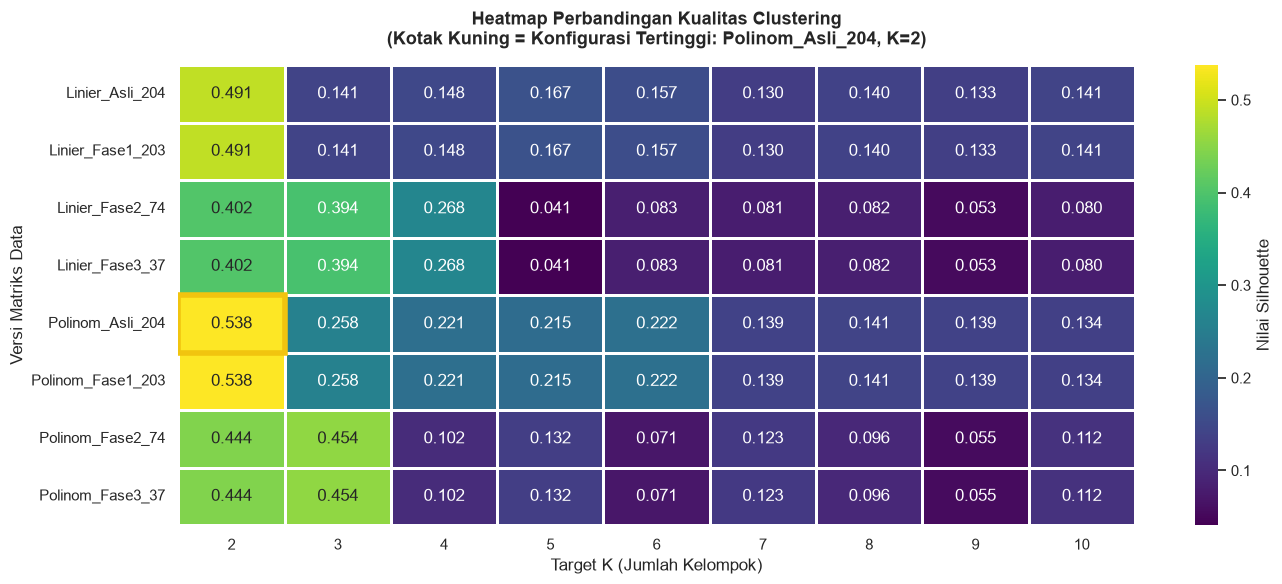

In [6]:
tabel_pivot = df_evaluasi.pivot(index='Entitas_Data', columns='Nilai_K', values='Skor_Silhouette')
urutan_baris = ['Linier_Asli_204', 'Linier_Fase1_203', 'Linier_Fase2_74', 'Linier_Fase3_37',
                'Polinom_Asli_204', 'Polinom_Fase1_203', 'Polinom_Fase2_74', 'Polinom_Fase3_37']
tabel_pivot = tabel_pivot.reindex(urutan_baris)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(tabel_pivot, annot=True, fmt='.3f', cmap='viridis', 
            linewidths=1, ax=ax, cbar_kws={'label': 'Nilai Silhouette'})

idx_dataset_juara = urutan_baris.index(DATASET_JUARA)
idx_k_juara = list(tabel_pivot.columns).index(K_JUARA)

# Menambahkan kotak emas untuk penanda jawara
import matplotlib.patches as patches
ax.add_patch(patches.Rectangle((idx_k_juara, idx_dataset_juara), 1, 1, 
                               fill=False, edgecolor='#f1c40f', lw=4, zorder=5))

judul_peta = f"Heatmap Perbandingan Kualitas Clustering\n(Kotak Kuning = Konfigurasi Tertinggi: {DATASET_JUARA}, K={K_JUARA})"
ax.set_title(judul_peta, fontweight='bold', fontsize=13, pad=15)
ax.set_ylabel('Versi Matriks Data')
ax.set_xlabel('Target K (Jumlah Kelompok)')

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '03_heatmap_silhouette.png'), dpi=120)
plt.show()


## 3.7 Evaluasi Keselarasan (Silhouette Plot) & Validasi Elbow

Untuk konfigurasi **terbaik global**, kita akan membongkar distribusinya secara mikroskopis (per sampel wilayah) menggunakan grafik pisau Silhouette dan memastikan bahwa K yang terpilih juga didukung oleh kaidah metode siku (Elbow).


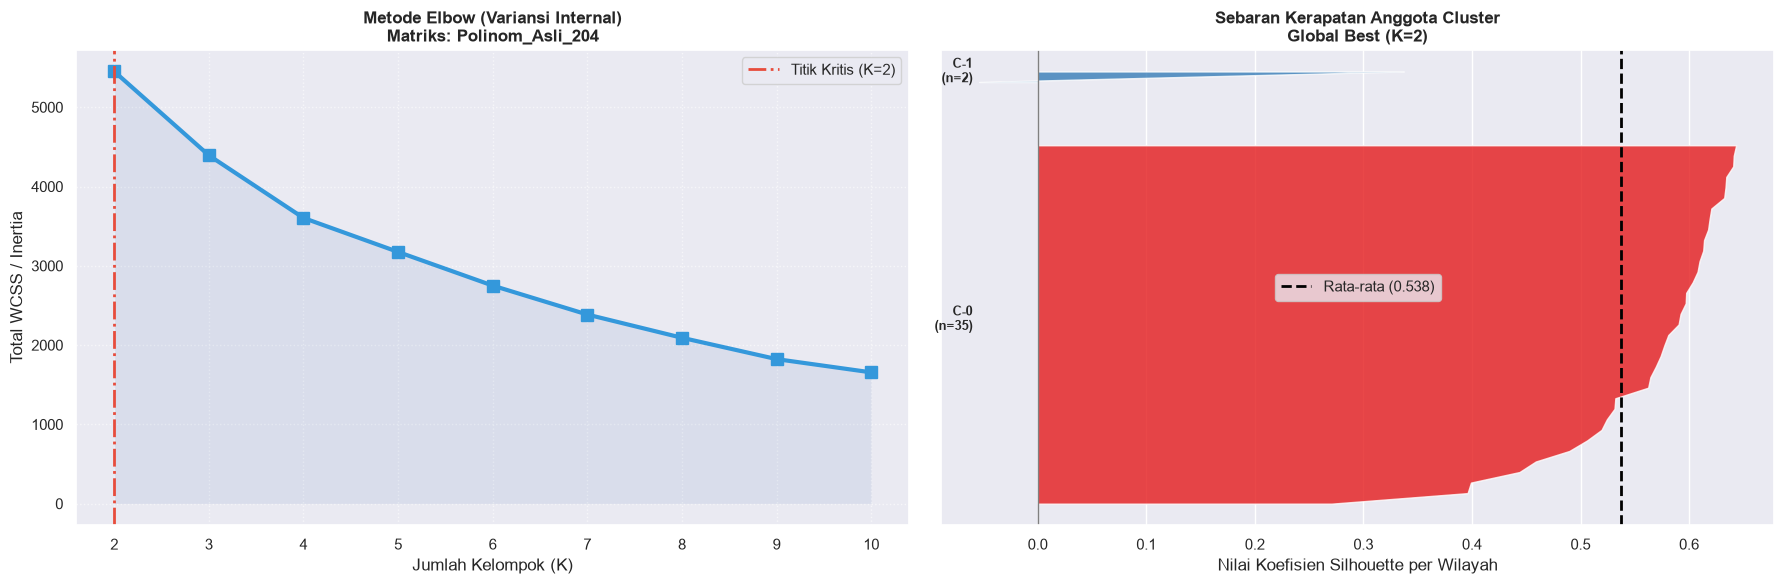

In [7]:
# Ekstrak data milik sang Juara
matriks_juara = kumpulan_matriks[DATASET_JUARA]
nilai_sil_individu = silhouette_samples(matriks_juara, LABEL_JUARA)

fig, (ax_elbow, ax_sil) = plt.subplots(1, 2, figsize=(18, 6))

# --- PLOT 1: ELBOW METHOD ---
potongan_juara = df_evaluasi[df_evaluasi['Entitas_Data'] == DATASET_JUARA]
ax_elbow.plot(potongan_juara['Nilai_K'], potongan_juara['Skor_Inertia'], 
              marker='s', color='#3498db', linewidth=3, markersize=8)
ax_elbow.fill_between(potongan_juara['Nilai_K'], potongan_juara['Skor_Inertia'], alpha=0.1)
ax_elbow.axvline(K_JUARA, color='#e74c3c', linestyle='-.', lw=2, label=f'Titik Kritis (K={K_JUARA})')

ax_elbow.set_title(f'Metode Elbow (Variansi Internal)\nMatriks: {DATASET_JUARA}', fontweight='bold')
ax_elbow.set_xlabel('Jumlah Kelompok (K)')
ax_elbow.set_ylabel('Total WCSS / Inertia')
ax_elbow.set_xticks(list(RENTANG_K))
ax_elbow.legend()
ax_elbow.grid(True, ls=':', alpha=0.6)

# --- PLOT 2: SILHOUETTE PLOT ---
batas_bawah = 10
palet_warna_cluster = sns.color_palette("Set1", K_JUARA)

for k_id in range(K_JUARA):
    skor_anggota = np.sort(nilai_sil_individu[LABEL_JUARA == k_id])
    kapasitas = len(skor_anggota)
    batas_atas = batas_bawah + kapasitas
    
    ax_sil.fill_betweenx(np.arange(batas_bawah, batas_atas), 0, skor_anggota,
                         facecolor=palet_warna_cluster[k_id], alpha=0.8)
    
    ax_sil.text(-0.06, batas_bawah + 0.5 * kapasitas, f"C-{k_id}\n(n={kapasitas})", 
                va='center', ha='right', fontweight='bold', fontsize=9)
    batas_bawah = batas_atas + 5

ax_sil.axvline(x=SILHOUETTE_JUARA, color='black', linestyle='--', linewidth=2, 
               label=f'Rata-rata ({SILHOUETTE_JUARA:.3f})')
ax_sil.axvline(x=0, color='grey', linewidth=1)

ax_sil.set_title(f'Sebaran Kerapatan Anggota Cluster\nGlobal Best (K={K_JUARA})', fontweight='bold')
ax_sil.set_xlabel('Nilai Koefisien Silhouette per Wilayah')
ax_sil.set_yticks([])
ax_sil.legend()

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '04_validasi_ganda_elbow_sil.png'), dpi=120)
plt.show()


## 3.8 Visualisasi Ruang 2D (PCA Scatter) & Komposisi Populasi

Bagaimana sebaran wilayah tersebut jika divisualisasikan dalam sumbu 2D? Kita menggunakan PCA 2 komponen hanya untuk keperluan plotting visual (bukan kalkulasi).


findfont: Failed to find font weight medium, now using 400.


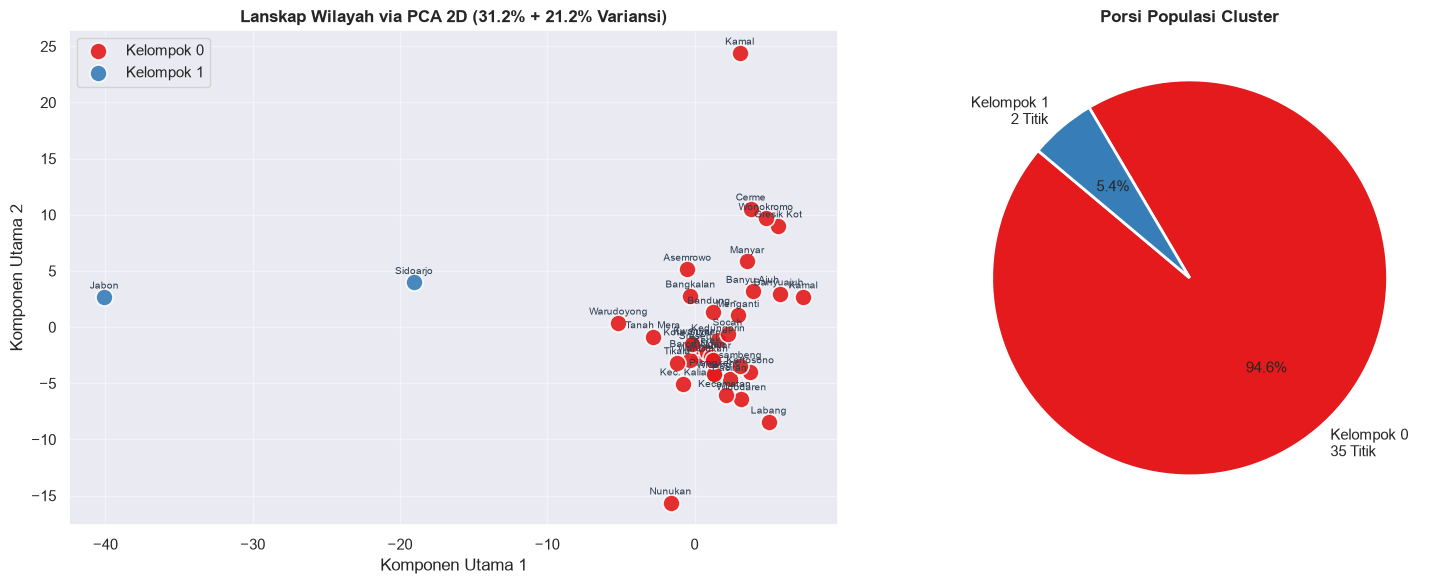

In [8]:
pca_visual = PCA(n_components=2, random_state=42)
proyeksi_2d = pca_visual.fit_transform(matriks_juara)
meta_referensi = meta_lin if 'Linier' in DATASET_JUARA else meta_pol

fig, (ax_scatter, ax_pie) = plt.subplots(1, 2, figsize=(16, 6))

# ---- Scatter Plot 2D ----
for cid in range(K_JUARA):
    indeks_anggota = (LABEL_JUARA == cid)
    ax_scatter.scatter(proyeksi_2d[indeks_anggota, 0], proyeksi_2d[indeks_anggota, 1], 
                       s=150, color=palet_warna_cluster[cid], edgecolor='white', 
                       linewidth=1.2, alpha=0.9, label=f'Kelompok {cid}')

# Menempelkan nama daerah pada titik scatter
for i, teks_daerah in enumerate(meta_referensi['daerah']):
    label_singkat = teks_daerah.split(',')[0][:10] # Ambil kecamatannya saja
    ax_scatter.annotate(label_singkat, (proyeksi_2d[i, 0], proyeksi_2d[i, 1]), 
                        xytext=(0, 6), textcoords='offset points', 
                        ha='center', fontsize=7, color='#2c3e50')

var_pc1 = pca_visual.explained_variance_ratio_[0] * 100
var_pc2 = pca_visual.explained_variance_ratio_[1] * 100

ax_scatter.set_title(f'Lanskap Wilayah via PCA 2D ({var_pc1:.1f}% + {var_pc2:.1f}% Variansi)', fontweight='bold')
ax_scatter.set_xlabel(f'Komponen Utama 1')
ax_scatter.set_ylabel(f'Komponen Utama 2')
ax_scatter.legend()
ax_scatter.grid(alpha=0.4)

# ---- Pie Chart ----
id_unik, porsi = np.unique(LABEL_JUARA, return_counts=True)
label_pie = [f'Kelompok {c}\n{jml} Titik' for c, jml in zip(id_unik, porsi)]

ax_pie.pie(porsi, labels=label_pie, colors=[palet_warna_cluster[c] for c in id_unik],
           autopct='%1.1f%%', startangle=140, wedgeprops={'edgecolor':'white', 'linewidth':2},
           textprops={'fontsize': 11, 'fontweight': 'medium'})
ax_pie.set_title(f'Porsi Populasi Cluster', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '05_distribusi_geometris.png'), dpi=120)
plt.show()


## 3.9 Bedah Profil Cluster (Analisis Rata-rata Fitur Polutan)

Langkah terakhir: mengintip karakteristik bawaan dari setiap cluster berdasarkan atribut mentah (NO2, SO2, CO) dari parameter sentral seperti Mean, Standar Deviasi, Entropy, dan Skewness. Angka yang tertera di peta suhu ini adalah nilai mentah, sedangkan pewarnaannya disesuaikan per rentang kolom.


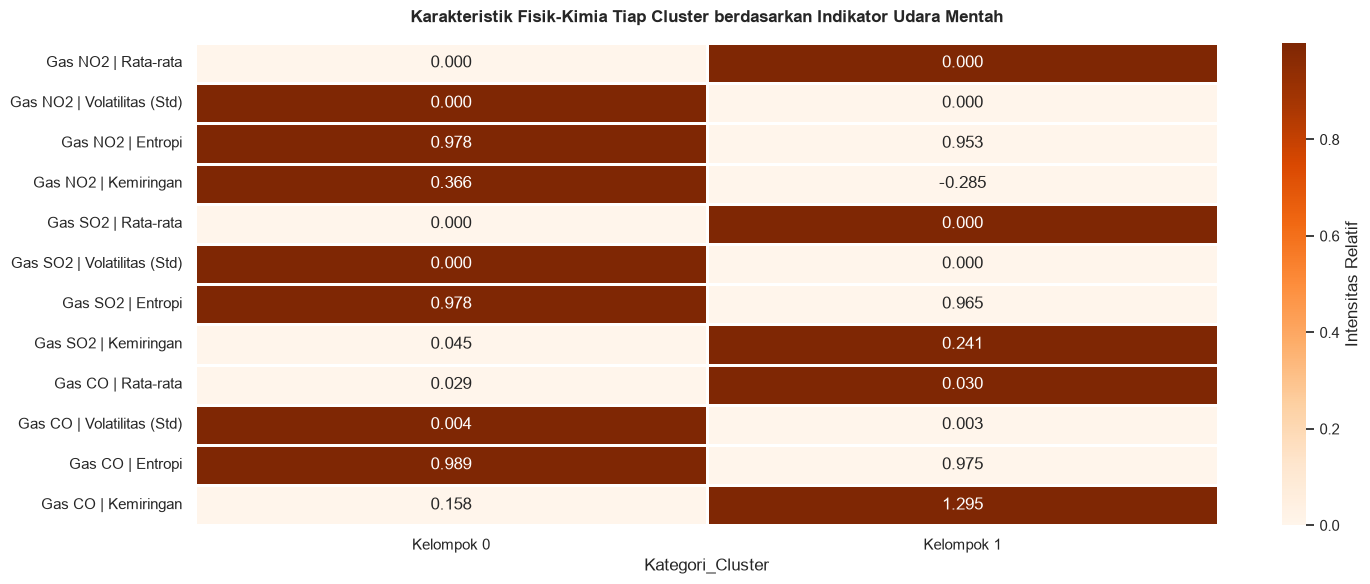

In [9]:
kolom_sorotan = []
label_fitur_tampil = []

df_mentah_rujukan = df_asli_lin if 'Linier' in DATASET_JUARA else df_asli_pol

senarai_polutan = [('no2', 'Gas NO2'), ('so2', 'Gas SO2'), ('co', 'Gas CO')]
senarai_metrik = [('calc_mean', 'Rata-rata'), ('calc_std', 'Volatilitas (Std)'), 
                  ('entropy', 'Entropi'), ('skewness', 'Kemiringan')]

for kode_p, nama_p in senarai_polutan:
    for kode_m, nama_m in senarai_metrik:
        nama_kolom = f"{kode_p}_{kode_m}"
        if nama_kolom in df_mentah_rujukan.columns:
            kolom_sorotan.append(nama_kolom)
            label_fitur_tampil.append(f"{nama_p} | {nama_m}")

df_analisis = df_mentah_rujukan[kolom_sorotan].copy()
df_analisis['Kategori_Cluster'] = LABEL_JUARA

pusat_massa = df_analisis.groupby('Kategori_Cluster').mean()

# Normalisasi Min-Max per atribut (untuk pewarnaan heatmap agar adil)
matriks_normalisasi = (pusat_massa - pusat_massa.min()) / (pusat_massa.max() - pusat_massa.min() + 1e-9)

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(matriks_normalisasi.T, annot=pusat_massa.T.round(3), fmt='.3f', 
            cmap='Oranges', linewidths=1, linecolor='white', ax=ax,
            cbar_kws={'label': 'Intensitas Relatif'})

ax.set_yticklabels(label_fitur_tampil, rotation=0)
ax.set_xticklabels([f"Kelompok {c}" for c in pusat_massa.index])
ax.set_title("Karakteristik Fisik-Kimia Tiap Cluster berdasarkan Indikator Udara Mentah", 
             fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '06_profil_karakteristik.png'), dpi=120)
plt.show()


## 3.10 Pengemasan Data Menuju Tahap 4

Kita menyimpan struktur pemenang beserta konfigurasi warnanya agar dapat divisualisasikan dalam wujud peta geografis di Tahap 4.


In [10]:
bundel_tahap3 = {
    'Dataset_Andalan': DATASET_JUARA,
    'K_Andalan': K_JUARA,
    'Sil_Andalan': SILHOUETTE_JUARA,
    'Label_Andalan': LABEL_JUARA,
    'Palet_Warna': palet_warna_cluster,
    'Metadata_Linier': meta_lin,
    'Metadata_Polinom': meta_pol,
    'Rekap_Evaluasi': df_evaluasi,
    'Tabel_Pemenang_Dimensi': df_stabilitas
}

lokasi_arsip = os.path.join(DIR_OUTPUT, 'paket_tahap3.pkl')
with open(lokasi_arsip, 'wb') as laci:
    pickle.dump(bundel_tahap3, laci)

print(f"✅ Paket sukses dikunci di: {os.path.abspath(lokasi_arsip)}")
print(f"📦 Berat File : {os.path.getsize(lokasi_arsip) / 1024:.2f} KB")

print("\n-> Anggota Kelompok 1 (C-0) Mayoritas:")
print(", ".join(meta_referensi['daerah'][LABEL_JUARA == 0].tolist()))

print("\nLuar biasa! Segmentasi K-Means telah membuktikan mana teknik preprocessing dan dimensi data yang paling padat informasi. Mari bersiap menuju pemetaan geografis di Tahap 4!")


✅ Paket sukses dikunci di: c:\Users\HYPE AMD\Documents\kuliah\psd\data\hasil_tahap3\paket_tahap3.pkl
📦 Berat File : 8.77 KB

-> Anggota Kelompok 1 (C-0) Mayoritas:
Baron Nganjuk, Nunukan, Sreseh, Sampang, Manyar, Gresik, Kamal, Bangkalan, Kedungpring Lamongan, Gresik Kota, Gresik, Waru, Pamekasan, Paciran, Lamongan, Kertosono, Nganjuk, Menganti, Gresik, Bandung - Jogoroto, Jombang, Banyu Ajuh, Perumnas, Kamal, Widang, Tuban, Kwanyar, Bangkalan, sambeng, lamongan, Kec. Kalianget, Sumenep, Cerme, Gresik, Tikala, Manado, Kerek, Tuban, Kwanyar, Bangkalan, Wonokromo, Surabaya, Asemrowo, Surabaya, Kota Sumenep, Sumenep, Socah, Bangkalan, Pilangkenceng, Madiun, Tanah Merah, Bangkalan, Labang, Bangkalan, Widodaren, Ngawi, Bangkalan, Bangkalan, Warudoyong, Kota Sukabumi, Kamal, Bangkalan, Banyuajuh kamal, Bangkalan, Dukun, Gresik, Kecamatan Bangkalan,Bangkalan

Luar biasa! Segmentasi K-Means telah membuktikan mana teknik preprocessing dan dimensi data yang paling padat informasi. Mari bersiap m